In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import tifffile as tiff
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap, BoundaryNorm
from skimage.filters import threshold_otsu, median
from skimage.morphology import opening, closing, disk
from scipy.stats import ttest_ind

# Example of generation of image masks

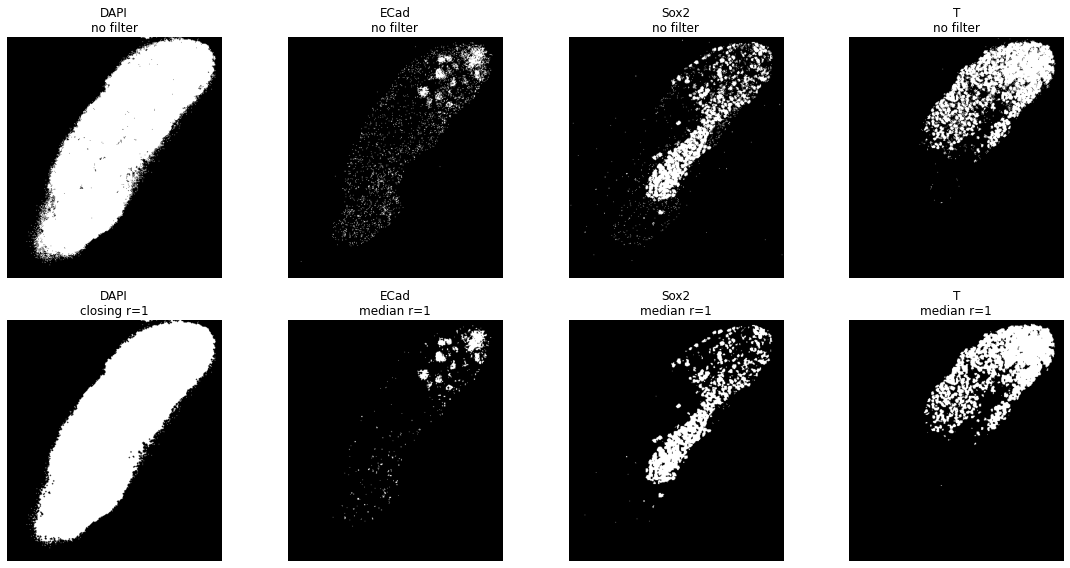

In [2]:

# ================= CONFIG =================
img_path = "../INPUT/Images/Immuno/Example_image/Example_immuno.tif"
Z_TO_SHOW = 37

CHANNELS = {
    "DAPI": 0,
    "ECad": 1,
    "Sox2": 2,
    "T": 3,
}

OTSU_MULT = {
    "DAPI": 0.3,
    "ECad": 3.5,
    "Sox2": 2,
    "T": 0.2,
}

FILTERS = {
    "DAPI": {"method": "closing", "radius": 1},
    "ECad": {"method": "median", "radius": 1},
    "Sox2": {"method": "median", "radius": 1},
    "T": {"method": "median", "radius": 1},
}
# ==========================================

# -------- Load image --------
arr = np.squeeze(tiff.imread(img_path))  # (Z, C, X, Y)
assert arr.ndim == 4

Z, C, X, Y = arr.shape
assert Z_TO_SHOW < Z

# -------- Filter helper --------
def apply_filter(mask, method, r):
    se = disk(r)
    if method == "opening":
        return opening(mask, se)
    if method == "closing":
        return closing(mask, se)
    if method == "median":
        return median(mask, se)
    return mask

# -------- Plot --------
fig, axes = plt.subplots(2, len(CHANNELS), figsize=(16, 8))

for col, (name, ch) in enumerate(CHANNELS.items()):
    img_all_z = arr[:, ch].astype(np.float32)

    vals = img_all_z.ravel()
    thr_otsu = threshold_otsu(vals) if np.any(vals != vals[0]) else np.inf
    thr = OTSU_MULT[name] * thr_otsu

    # ---- raw mask ----
    mask_z = img_all_z[Z_TO_SHOW] > thr
    axes[0, col].imshow(mask_z, cmap="gray")
    axes[0, col].set_title(f"{name}\nno filter")
    axes[0, col].axis("off")

    # ---- filtered mask ----
    fcfg = FILTERS[name]
    mask_filt = apply_filter(mask_z, fcfg["method"], fcfg["radius"])
    axes[1, col].imshow(mask_filt, cmap="gray")
    axes[1, col].set_title(f"{name}\n{fcfg['method']} r={fcfg['radius']}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()


# Example: Cell type annotation

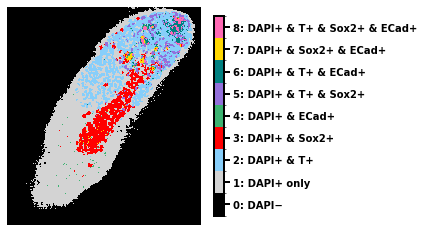

In [3]:


# =========================================================
# We assume these already exist from the previous code:
#   mask_filt for each channel at z = Z_TO_SHOW
# Here we just recompute them inline from the same variables
# =========================================================

# --- Build combined label image ---
# binary masks at z (FILTERED)
m_dapi = None
m_ecad = None
m_sox2 = None
m_t = None

for name, ch in CHANNELS.items():
    img_all_z = arr[:, ch].astype(np.float32)
    vals = img_all_z.ravel()
    thr_otsu = threshold_otsu(vals) if np.any(vals != vals[0]) else np.inf
    thr = OTSU_MULT[name] * thr_otsu

    mask_z = img_all_z[Z_TO_SHOW] > thr
    fcfg = FILTERS[name]
    mask_filt = apply_filter(mask_z, fcfg["method"], fcfg["radius"])

    if name == "DAPI":
        m_dapi = mask_filt
    elif name == "ECad":
        m_ecad = mask_filt
    elif name == "Sox2":
        m_sox2 = mask_filt
    elif name == "T":
        m_t = mask_filt

# --- Encode combinations (0–8) ---
labels = np.zeros_like(m_dapi, dtype=np.uint8)

labels[m_dapi] = 1
labels[m_dapi & m_t] = 2
labels[m_dapi & m_sox2] = 3
labels[m_dapi & m_ecad] = 4
labels[m_dapi & m_t & m_sox2] = 5
labels[m_dapi & m_t & m_ecad] = 6
labels[m_dapi & m_sox2 & m_ecad] = 7
labels[m_dapi & m_t & m_sox2 & m_ecad] = 8

# --- Colormap ---
colors = [
    "black",          # 0: DAPI-
    "lightgrey",      # 1: DAPI+ only
    "lightskyblue",   # 2: DAPI+ & T+
    "red",            # 3: DAPI+ & Sox2+
    "mediumseagreen", # 4: DAPI+ & ECad+
    "mediumpurple",   # 5: DAPI+ & T+ & Sox2+
    "teal",           # 6: DAPI+ & T+ & ECad+
    "gold",           # 7: DAPI+ & Sox2+ & ECad+
    "hotpink"         # 8: DAPI+ & T+ & Sox2+ & ECad+
]
cmap = ListedColormap(colors)
bounds = np.arange(-0.5, 9.5, 1.0)
norm = BoundaryNorm(bounds, cmap.N)

tick_labels = [
    "0: DAPI−",
    "1: DAPI+ only",
    "2: DAPI+ & T+",
    "3: DAPI+ & Sox2+",
    "4: DAPI+ & ECad+",
    "5: DAPI+ & T+ & Sox2+",
    "6: DAPI+ & T+ & ECad+",
    "7: DAPI+ & Sox2+ & ECad+",
    "8: DAPI+ & T+ & Sox2+ & ECad+",
]

# --- Plot ---
plt.figure(figsize=(6, 6))
im = plt.imshow(labels, cmap=cmap, norm=norm, interpolation="nearest")

cbar = plt.colorbar(im, ticks=range(9), fraction=0.046, pad=0.06)
cbar.ax.set_yticklabels(tick_labels, fontsize=10, fontweight="bold")
cbar.ax.tick_params(length=6, width=2)
for spine in cbar.ax.spines.values():
    spine.set_linewidth(2)

plt.axis("off")
plt.tight_layout()
plt.show()


# Quantification of cell types accross conditions 

### Natural scale

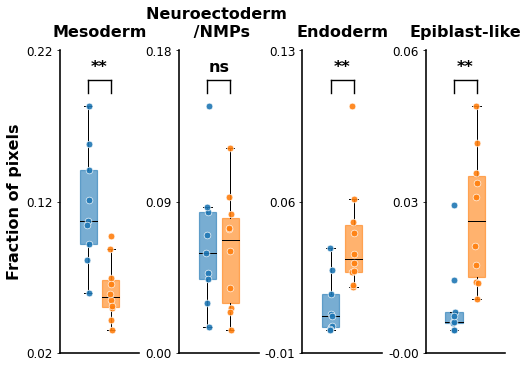

In [4]:


# ---------------- CONFIG ----------------
FS = {"ylabel": 16, "ticks": 12, "legend": 12, "title": 16, "sig": 16}
TITLE_PAD = 14

merged_dir = Path("../INPUT/Images/Immuno/Masks")
out_path   = Path("/Users/mleonard/Documents/Gastruloid_Paper/Paper_Submission/Figures/Figure1/Image_prop.png")

# Focused lineages
focus = {2: "Mesoderm", 3: "Neuroectoderm \n /NMPs", 4: "Endoderm", 7: "Epiblast-like"}
group_order = list(focus.keys())

# Colors for conditions
cond_labels = ["Control", "CDK4/6 inhibitor"]
cond_colors = ["tab:blue", "tab:orange"]
box_alpha = 0.6
rng = np.random.default_rng(42)

def p_to_stars(p):
    return "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 5e-2 else "ns"

# ---------------- LOAD DATA & COMPUTE RATIOS ----------------
rows = []
for fp in sorted(merged_dir.glob("*.tif")):
    if fp.name.startswith(("._", ".")):
        continue
    parts = fp.stem.split("_")
    if len(parts) < 2: 
        continue
    condition, obj = parts[0].lower(), parts[1]
    if condition not in {"ctrl", "cdk"}:
        continue

    arr = tiff.imread(fp).ravel()
    dapi_pos = arr > 0
    total = int(dapi_pos.sum())
    if total == 0:
        continue

    counts = {i: int((arr == i).sum()) for i in range(1, 9)}
    ratios = {f"ratio_{i}": counts[i] / total for i in range(1, 9)}
    rows.append({"condition": condition, "object": obj, **ratios})

df = pd.DataFrame(rows)
assert not df.empty, "No ctrl/cdk merged masks found."

# ---------------- PREPARE DATA PER GROUP (no log) ----------------
data_per_group = {}
for i in group_order:
    key = f"ratio_{i}"
    ctrl_vals = df.loc[df["condition"] == "ctrl", key].values
    cdk_vals  = df.loc[df["condition"] == "cdk",  key].values
    data_per_group[i] = (ctrl_vals, cdk_vals)

# ---------------- FIGURE ----------------
fig, axes = plt.subplots(1, 4, figsize=(7, 5), constrained_layout=True, sharey=False)

for k, (ax, gid) in enumerate(zip(axes, group_order)):
    ctrl_vals, cdk_vals = data_per_group[gid]

    # Box positions
    positions = [0.8, 1.2]
    widths = 0.3

    # Dynamic y-limits
    y_all = np.concatenate([ctrl_vals, cdk_vals]) if ctrl_vals.size and cdk_vals.size else np.array([0])
    ymin, ymax = y_all.min(), y_all.max()
    span = max(ymax - ymin, 0.01)  # avoid zero span
    ax.set_ylim(ymin - 0.1*span, ymax + 0.25*span)

    # ---------------- BOX PLOT ----------------
    bp = ax.boxplot([ctrl_vals, cdk_vals], positions=positions, widths=widths,
                    patch_artist=True, showfliers=False)
    for idx, patch in enumerate(bp['boxes']):
        patch.set_facecolor(cond_colors[idx % 2])
        patch.set_alpha(box_alpha)
        patch.set_edgecolor(cond_colors[idx % 2])
        patch.set_linewidth(1.2)
    for element in ['whiskers', 'caps', 'medians']:
        for line in bp[element]:
            line.set_color('black')
            line.set_linewidth(1.0)

    # Scatter points with jitter
    for j, vals in enumerate([ctrl_vals, cdk_vals]):
        if vals.size:
            jitter = (rng.random(len(vals)) - 0.5) * 0.05
            ax.scatter(np.full(len(vals), positions[j]) + jitter, vals,
                       s=45, color=cond_colors[j], alpha=0.9,
                       edgecolors='white', linewidths=0.7, zorder=3)

    # ---------------- SIGNIFICANCE ----------------
    if ctrl_vals.size and cdk_vals.size:
        _, p = ttest_ind(ctrl_vals, cdk_vals, equal_var=False)
        y_span = ax.get_ylim()[1] - ax.get_ylim()[0]
        y_top = ax.get_ylim()[1] - 0.1*y_span
        y_base = y_top - 0.04*y_span
        x1, x2 = positions
        ax.plot([x1, x1], [y_base, y_top], color="black", lw=1.4)
        ax.plot([x2, x2], [y_base, y_top], color="black", lw=1.4)
        ax.plot([x1, x2], [y_top, y_top], color="black", lw=1.4)
        ax.text((x1+x2)/2, y_top + 0.02*y_span, p_to_stars(p),
                ha="center", va="bottom", fontsize=FS["sig"], fontweight="bold")

    # Axis styling
    ax.set_xticks([])
    ax.set_xlabel("")
    ticks = np.linspace(*ax.get_ylim(), 3)
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{t:.2f}" for t in ticks])
    ax.tick_params(axis='y', labelsize=FS["ticks"], left=True)

    if k == 0:
        ax.set_ylabel("Fraction of pixels", fontsize=FS["ylabel"], fontweight="bold")
    ax.set_title(focus[gid], fontsize=FS["title"], fontweight="bold", pad=TITLE_PAD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.6)
    ax.spines['bottom'].set_linewidth(1.6)

# ---------------- SAVE & SHOW ----------------
fig.savefig(out_path, dpi=400, bbox_inches="tight", pad_inches=0)
plt.show()


### Log scale

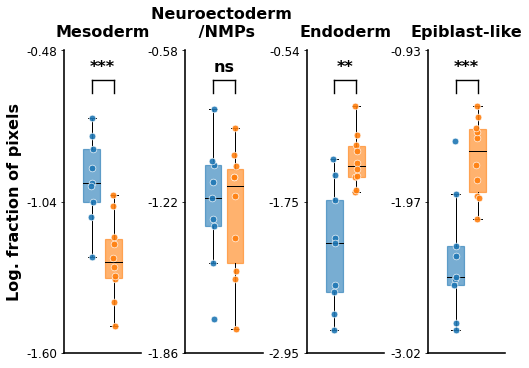

In [5]:


# ---------------- CONFIG ----------------
FS = {"ylabel": 16, "ticks": 12, "legend": 12, "title": 16, "sig": 16}  # font sizes
TITLE_PAD = 14  # space between title and axes

merged_dir = Path("../INPUT/Images/Immuno/Masks")
out_path   = Path("/Users/mleonard/Documents/Gastruloid_Paper/Paper_Submission/Figures/Figure1/Image_prop_log.png")

# Focused lineages: label index -> name
focus = {2: "Mesoderm", 3: "Neuroectoderm \n /NMPs", 4: "Endoderm", 7: "Epiblast-like"}
group_order = list(focus.keys())

# Colors for conditions
cond_labels = ["Control", "CDK4/6 inhibitor"]
cond_colors = ["tab:blue", "tab:orange"]
box_alpha = 0.6
EPS = 1e-6
rng = np.random.default_rng(42)

def p_to_stars(p):
    return "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 5e-2 else "ns"

# ---------------- LOAD DATA & COMPUTE RATIOS ----------------
rows = []
for fp in sorted(merged_dir.glob("*.tif")):
    if fp.name.startswith(("._", ".")):
        continue
    parts = fp.stem.split("_")
    if len(parts) < 2: 
        continue
    condition, obj = parts[0].lower(), parts[1]
    if condition not in {"ctrl", "cdk"}:
        continue

    arr = tiff.imread(fp).ravel()
    dapi_pos = arr > 0
    total = int(dapi_pos.sum())
    if total == 0:
        continue

    counts = {i: int((arr == i).sum()) for i in range(1, 9)}
    ratios = {f"ratio_{i}": counts[i] / total for i in range(1, 9)}
    rows.append({"condition": condition, "object": obj, **ratios})

df = pd.DataFrame(rows)
assert not df.empty, "No ctrl/cdk merged masks found."

# ---------------- PREPARE LOG10 DATA PER GROUP ----------------
data_per_group = {}
for i in group_order:
    key = f"ratio_{i}"
    ctrl_vals = df.loc[df["condition"] == "ctrl", key].values
    cdk_vals  = df.loc[df["condition"] == "cdk",  key].values
    data_per_group[i] = (np.log10(np.clip(ctrl_vals, EPS, None)),
                         np.log10(np.clip(cdk_vals,  EPS, None)))

# ---------------- FIGURE ----------------
fig, axes = plt.subplots(1, 4, figsize=(7, 5), constrained_layout=True, sharey=False)

for k, (ax, gid) in enumerate(zip(axes, group_order)):
    ctrl_log, cdk_log = data_per_group[gid]

    # Box positions
    positions = [0.8, 1.2]
    widths = 0.3

    # Dynamic y-limits with padding
    y_all = np.concatenate([ctrl_log, cdk_log]) if ctrl_log.size and cdk_log.size else np.array([0])
    ymin, ymax = y_all.min(), y_all.max()
    span = max(ymax - ymin, 1.0)
    ax.set_ylim(ymin - 0.1*span, ymax + 0.25*span)

    # ---------------- BOX PLOT ----------------
    bp = ax.boxplot([ctrl_log, cdk_log], positions=positions, widths=widths,
                    patch_artist=True, showfliers=False)
    for idx, patch in enumerate(bp['boxes']):
        patch.set_facecolor(cond_colors[idx % 2])
        patch.set_alpha(box_alpha)
        patch.set_edgecolor(cond_colors[idx % 2])
        patch.set_linewidth(1.2)
    for element in ['whiskers', 'caps', 'medians']:
        for line in bp[element]:
            line.set_color('black')
            line.set_linewidth(1.0)

    # Scatter individual points with jitter
    for j, vals in enumerate([ctrl_log, cdk_log]):
        if vals.size:
            jitter = (rng.random(len(vals)) - 0.5) * 0.05
            ax.scatter(np.full(len(vals), positions[j]) + jitter, vals,
                       s=45, color=cond_colors[j], alpha=0.9,
                       edgecolors='white', linewidths=0.7, zorder=3)

    # ---------------- SIGNIFICANCE ----------------
    if ctrl_log.size and cdk_log.size:
        _, p = ttest_ind(ctrl_log, cdk_log, equal_var=False)
        y_span = ax.get_ylim()[1] - ax.get_ylim()[0]
        y_top = ax.get_ylim()[1] - 0.1*y_span
        y_base = y_top - 0.04*y_span
        x1, x2 = positions
        ax.plot([x1, x1], [y_base, y_top], color="black", lw=1.4)
        ax.plot([x2, x2], [y_base, y_top], color="black", lw=1.4)
        ax.plot([x1, x2], [y_top, y_top], color="black", lw=1.4)
        ax.text((x1+x2)/2, y_top + 0.02*y_span, p_to_stars(p),
                ha="center", va="bottom", fontsize=FS["sig"], fontweight="bold")

    # Axis styling
    ax.set_xticks([])
    ax.set_xlabel("")
    ticks = np.linspace(*ax.get_ylim(), 3)
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{t:.2f}" for t in ticks])
    ax.tick_params(axis='y', labelsize=FS["ticks"], left=True)

    if k == 0:
        ax.set_ylabel("Log. fraction of pixels", fontsize=FS["ylabel"], fontweight="bold")
    ax.set_title(focus[gid], fontsize=FS["title"], fontweight="bold", pad=TITLE_PAD)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.6)
    ax.spines['bottom'].set_linewidth(1.6)

# ---------------- SAVE & SHOW ----------------
fig.savefig(out_path, dpi=400, bbox_inches="tight", pad_inches=0)
plt.show()
